# Linear Regression Model

In [1]:
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

%matplotlib inline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from EDA_and_modeling.functional_files import _featuring, _data, _model_impex, _evaluating
import importlib
importlib.reload(_data)
importlib.reload(_featuring)
importlib.reload(_evaluating)
importlib.reload(_model_impex)

print('Libraries loaded!')

pd.set_option('display.max_rows', None)      # all rows
pd.set_option('display.max_columns', None)   # all columns
pd.set_option('display.width', None)         # no line wrapping
pd.set_option('display.max_colwidth', None)  # don't truncate cell contents

Data File: Libraries loaded!
Featuring File: Libraries loaded!
Featuring File: Libraries loaded!
Featuring File: Libraries loaded!
Data File: Libraries loaded!
Featuring File: Libraries loaded!
Libraries loaded!


In [2]:
def sp(two_lines = True):
    print("==========================")
    if (two_lines):
        print()
        print("==========================")

## Data

In [3]:
df, _ = _data.get_data('1')

In [4]:
x = df.drop(columns='is_fraud')
y = df['is_fraud']

In [5]:
x_temp_raw, x_test_raw, y_temp, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
x_train_raw, x_val_raw, y_train, y_val = train_test_split(x_temp_raw, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

In [6]:
x_train_raw = _featuring.simple(x_train_raw)
x_val_raw = _featuring.simple(x_val_raw)
x_test_raw = _featuring.simple(x_test_raw)

## Model

In [7]:
IMPORT_MODEL = True
model_name = "10_simple_regression"

In [8]:
if IMPORT_MODEL:
    dv, model = _model_impex.import_model(model_name)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    x_test = _model_impex.dv_transform(dv, x_test_raw)
else:
    dv = _model_impex.dv_initializing(x_train_raw)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    x_test = _model_impex.dv_transform(dv, x_test_raw)

    model = LogisticRegression()
    model.fit(x_train, y_train)

    _model_impex.export_model(model_name, dv, model)

In [9]:
predicted = model.predict_proba(x_val)[:, 1]

In [10]:
_evaluating.full_score(y_val, predicted)

ROC AUC: 0.7501993474595179
PR AUC: 0.06361005086964426


{'roc-auc': 0.7501993474595179, 'pr-auc': 0.06361005086964426}

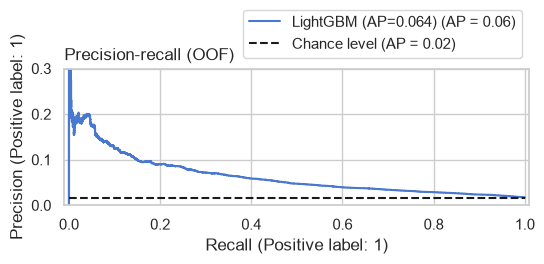

In [11]:
_evaluating.plot_pr_auc(y_val, predicted)

In [12]:
_evaluating.noise_check(y_val, predicted)

[0.0582641  0.07105451]


#### Conclusion 3
The baseline
Model performs (PR-AUC = 0.063) better than the baseline (PR-AUC = 0.016).

Noise check also shows that the model found some real signals.